In [1]:
!pip install matplotlib


In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


In [2]:
from sklearn.utils import class_weight
# y_train_labels must be integer class indices of training set
cw = class_weight.compute_class_weight('balanced', classes=np.unique(y_train_labels), y=y_train_labels)
class_weight_dict = dict(enumerate(cw))
model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight_dict)


NameError: name 'np' is not defined

In [ ]:
from tensorflow.keras.preprocessing import image_dataset_from_directory

train_ds = image_dataset_from_directory(r"C:\Users\m8494\Downloads\dataset", image_size=(224,224))
print("Class Names:", train_ds.class_names)

train_ds = image_dataset_from_directory(r"C:\Users\m8494\Downloads\dataset")


In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50, resnet50
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
import os


In [5]:
# Create train & val datasets (no prefetch yet)
train_ds = image_dataset_from_directory(
    r"C:\Users\m8494\Downloads\dataset",
    subset='training',
    validation_split=0.2,
    image_size=(224,224),
    batch_size=32,
    seed=123
)

val_ds = image_dataset_from_directory(
    r"C:\Users\m8494\Downloads\dataset",
    subset='validation',
    validation_split=0.2,
    image_size=(224,224),
    batch_size=32,
    seed=123
)

# ✔️ Get number of classes BEFORE prefetch
num_classes = len(train_ds.class_names)
print("Classes:", train_ds.class_names)
print("num_classes:", num_classes)

# Now apply prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)


Found 900 files belonging to 3 classes.
Using 720 files for training.
Found 900 files belonging to 3 classes.
Using 180 files for validation.
Classes: ['test', 'train', 'val']
num_classes: 3


In [ ]:
preprocess_input = resnet50.preprocess_input

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

AUTOTUNE = tf.data.AUTOTUNE

def prepare(ds, training=False):
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x), y), num_parallel_calls=AUTOTUNE)
        ds = ds.shuffle(1000)
    return ds.prefetch(buffer_size=AUTOTUNE)

train_ds = prepare(train_ds, training=True)
val_ds = prepare(val_ds)
test_ds = prepare(test_ds)


In [ ]:
# Number of classes
num_classes = len(train_ds.class_names)

from tensorflow.keras.applications import ResNet50
base = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
base.trainable = False  # freeze initially

from tensorflow.keras import layers, models

inputs = layers.Input(shape=(224,224,3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.summary()


In [ ]:
# Unfreeze last N layers
for layer in base.layers[-50:]:
    layer.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# Train with a lower LR and suitable callbacks


opt = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])



layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))


In [3]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
    layers.RandomCrop(200,200)  # if you also resize afterwards
])
# Apply to train dataset only
train_ds = train_ds.map(lambda x,y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)


NameError: name 'layers' is not defined

In [33]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("best_resnet50_model.h5", save_best_only=True, monitor="val_accuracy", mode="max"),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1)
]


In [42]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[reduce_lr]
)


Epoch 1/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 22s 284ms/step - accuracy: 0.6433 - loss: 0.8319 - val_accuracy: 0.6600 - val_loss: 0.7856 - learning_rate: 5.0000e-04
Epoch 2/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 22s 285ms/step - accuracy: 0.6467 - loss: 0.7989 - val_accuracy: 0.7033 - val_loss: 0.7008 - learning_rate: 5.0000e-04
Epoch 3/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 22s 283ms/step - accuracy: 0.6567 - loss: 0.8096 - val_accuracy: 0.6467 - val_loss: 0.7831 - learning_rate: 5.0000e-04
Epoch 4/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 22s 283ms/step - accuracy: 0.6400 - loss: 0.7983 - val_accuracy: 0.6567 - val_loss: 0.8003 - learning_rate: 2.5000e-04
Epoch 5/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 23s 291ms/step - accuracy: 0.6833 - loss: 0.7313 - val_accuracy: 0.6967 - val_loss: 0.7308 - learning_rate: 2.5000e-04
Epoch 6/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 23s 290ms/step - accuracy: 0.6800 - loss: 0.6936 - val_accuracy: 0.7000 - val_loss: 0.7517 - learning_rate: 2.5000e-04
Epoch 7/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 23s 288ms/step - acc

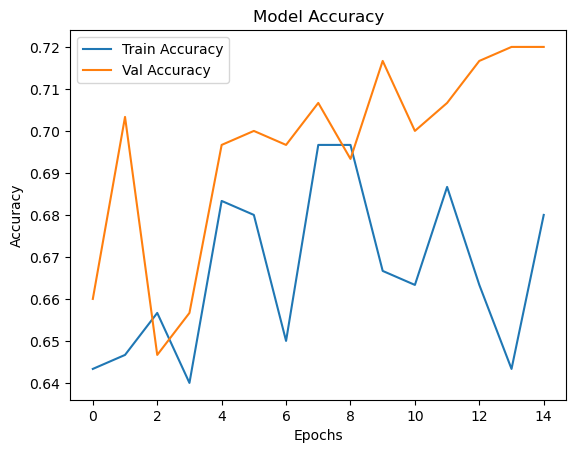

In [43]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [44]:
model.load_weights("best_resnet50_model.h5")
test_loss, test_acc = model.evaluate(test_ds)
print(f"✅ Test Accuracy: {test_acc*100:.2f}%")


75/75 ━━━━━━━━━━━━━━━━━━━━ 11s 149ms/step - accuracy: 0.5800 - loss: 1.0569
✅ Test Accuracy: 58.00%


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_image(path):
    img = image.load_img(path, target_size=(224,224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = resnet50.preprocess_input(x)
    preds = model.predict(x)
    predicted_class = class_names[np.argmax(preds)]
    print(f"Predicted Grade: {predicted_class}")

from pathlib import Path

img_path = Path(r"C:\Users\sanjk\Downloads\IMG_20251012_110358.jpg")
predict_image(str(img_path))
